In [2]:
!pip install datasets

  Obtaining dependency information for datasets from https://files.pythonhosted.org/packages/d3/95/ef83542e7a8e2bfc4432ee2cd8a6b52eb30fb1e605871e8871e94ce65fb1/datasets-2.13.2-py3-none-any.whl.metadata
  Obtaining dependency information for dill<0.3.7,>=0.3.0 from https://files.pythonhosted.org/packages/be/e3/a84bf2e561beed15813080d693b4b27573262433fced9c1d1fea59e60553/dill-0.3.6-py3-none-any.whl.metadata
  Obtaining dependency information for xxhash from https://files.pythonhosted.org/packages/21/57/75804858815f1f005dc8f6ca09266c14fbc8ba8ad836a6f8794f180394a0/xxhash-3.5.0-cp37-cp37m-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata
  Obtaining dependency information for multiprocess from https://files.pythonhosted.org/packages/ca/3f/8354ce12fd13bd5c5bb4722261a10ca1d6e2eb7c1c08fa3d8a4e9dc98f44/multiprocess-0.70.15-py37-none-any.whl.metadata
  Obtaining dependency information for huggingface-hub<1.0.0,>=0.11.0 from https://files.pythonhosted.org/packages/7f/c4/adcbe9a696c135578cab

In [1]:
from datasets import load_dataset

ds = load_dataset("Marqo/fashion200k")

Found cached dataset parquet (/home/abhisheksureddy/.cache/huggingface/datasets/Marqo___parquet/Marqo--fashion200k-e452c40783d60867/0.0.0/14a00e99c0d15a23649d0db8944380ac81082d4b021f398733dd84f3a6c569a7)


  0%|          | 0/1 [00:00<?, ?it/s]

In [5]:
ds.keys()

dict_keys(['data'])

In [6]:
ds['data']

Dataset({
    features: ['image', 'category1', 'category2', 'category3', 'text', 'item_ID'],
    num_rows: 201624
})

In [7]:
ds['data'][0]

{'image': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=266x430>,
 'category1': 'dresses',
 'category2': 'mini and short dresses',
 'category3': 'green seamed a-line dress',
 'text': 'green dress. the dress is made of a shiny material and has a boat neckline. it is a short dress with a straight cut and is worn by a woman.',
 'item_ID': '51727804_0'}

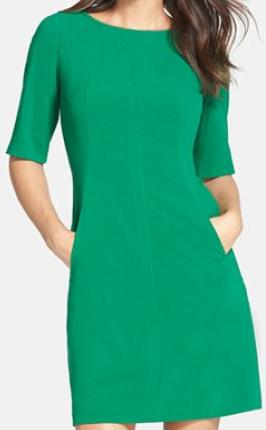

In [8]:
ds['data'][0]['image']

## Storing Fashion200k in GCS

In [2]:
import os
from google.cloud import storage

In [3]:
# store the data in gcp bucket
os.environ["GOOGLE_APPLICATION_CREDENTIALS"] = "/home/abhisheksureddy/sharp-messenger-444918-a4-538e8b5aecdb.json"
bucket_name = "cs-data-bucket-1"
# Initialize a GCP client
# storage_client = storage.Client()

# # Get the bucket
# bucket = storage_client.bucket(bucket_name)
# blob = bucket.blob("sample_image.png")
# # img.save("sample_image.png")
# blob.upload_from_filename("sample_image.png")

In [4]:
import io
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
from google.cloud import storage

# Initialize Google Cloud Storage Client
def get_storage_client():
    return storage.Client()

# Function to upload a single image
def upload_image(image_obj, bucket_name, destination_blob_name):
    """Uploads an in-memory PIL image object to GCP bucket."""
    client = get_storage_client()
    bucket = client.bucket(bucket_name)
    blob = bucket.blob(destination_blob_name)

    # Convert the PIL image to an in-memory binary stream
    with io.BytesIO() as image_stream:
        image_obj.save(image_stream, format="PNG")  # Specify the desired format
        image_stream.seek(0)
        blob.upload_from_file(image_stream, content_type="image/png")
    
    # print(f"Uploaded {destination_blob_name}")

# Function to upload multiple images in parallel
def upload_images_parallel(images, bucket_name, folder_name):
    """
    Uploads a list of PIL image objects to a GCP bucket in parallel.
    images: list of (PIL.Image, str) where str is the image name.
    bucket_name: GCP bucket name.
    folder_name: Destination folder in the bucket.
    """
    with ThreadPoolExecutor() as executor:
        futures = []
        for image_obj, image_name in images:
            # Define the destination path
            destination_blob_name = f"{folder_name}/{image_name}"
            futures.append(executor.submit(upload_image, image_obj, bucket_name, destination_blob_name))
        
        # Wait for all uploads to complete
        for future in futures:
            future.result()  # Raise exceptions if any occur


In [5]:
folder_name = "fashion200k"

In [16]:

# # Example images (replace with actual PIL Image objects)
# image1 = Image.new("RGB", (100, 100), color="red")
# image2 = Image.new("RGB", (100, 100), color="blue")
# image3 = Image.new("RGB", (100, 100), color="green")

# # List of images and their names
# images = [(image1, "red.png"), (image2, "blue.png"), (image3, "green.png")]


# # Upload images
# upload_images_parallel(images, bucket_name, folder_name)

Uploaded fashion200k/blue.png
Uploaded fashion200k/red.png
Uploaded fashion200k/green.png


In [6]:
from torch.utils.data import DataLoader
from tqdm import tqdm

In [7]:
def custom_collate_fn(batch):
    images = [item['image'] for item in batch]
    ids = [f"{item['item_ID']}.png" for item in batch]
    return images, ids

In [8]:
dataloader = DataLoader(ds['data'], batch_size=200, collate_fn=custom_collate_fn)

In [16]:
i = 0
for batch in tqdm(dataloader):
    if i == 57 or i==58:
        images, filenames = batch
        ims = [(im,fname) for im,fname in zip(images, filenames)]
        
        upload_images_parallel(ims, bucket_name, folder_name)
    i += 1

  9%|▉         | 92/1009 [00:20<03:29,  4.39it/s]


KeyboardInterrupt: 

In [12]:
i = 0
for batch in tqdm(dataloader):
    if i > 577:
        images, filenames = batch
        ims = [(im,fname) for im,fname in zip(images, filenames)]
        
        upload_images_parallel(ims, bucket_name, folder_name)
    i += 1

100%|██████████| 1009/1009 [36:09<00:00,  2.15s/it]


In [14]:
len(ds['data'])

201624